In [109]:
import os 
from pathlib import Path
from dotenv import load_dotenv

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from matplotlib.ticker import MaxNLocator
load_dotenv(override=True);

In [49]:
data_repo_env = os.getenv('DATA_REPO_PATH')
DATA_REPO_DIR = Path(data_repo_env)

matchescsv = DATA_REPO_DIR / "GW7" / "matches.csv"
teamscsv = DATA_REPO_DIR / "GW7" / "teams.csv"

matches = pd.read_csv(matchescsv)
teams = pd.read_csv(teamscsv)

In [50]:
playerstatscsv = DATA_REPO_DIR / "GW7" / "playermatchstats.csv"
playerscsv = DATA_REPO_DIR / "GW7" / "players.csv"

playermatchstats = pd.read_csv(playerstatscsv)
players = pd.read_csv(playerscsv)

playermatchstats["team_code"] = playermatchstats["player_id"].map(
    players.set_index("player_id")["team_code"]
)

In [51]:
team_sprint = playermatchstats.groupby("team_code").agg(
    total_sprints = ("number_of_sprints", "sum"), 
    avg_distance_cov = ("distance_covered", "mean")
).round(1).reset_index()

In [52]:
teams = teams[["code", "short_name"]]

In [53]:
metrics = ["total_shots",
           "accurate_passes",
           "shots_inside_box",
           "clearances",
           "duels_won",
           "successful_dribbles"]

home_met = [f"home_{m}" for m in metrics]
away_met = [f"away_{m}" for m in metrics]

home_stats = matches.groupby("home_team")[home_met].sum()
away_stats = matches.groupby("away_team")[away_met].sum()



In [54]:
home_stats.columns = metrics
away_stats.columns = metrics

In [55]:
total_stats = home_stats.add(away_stats, fill_value=0)

In [56]:
teams = teams.merge(
    total_stats,
    left_on = "code",
    right_index=True,
    how="left"
).fillna(0)

In [57]:
teams["number_of_sprints"] = teams["code"].map(
    team_sprint.set_index("team_code")["total_sprints"]
)
teams["avg_distance_cov"] = teams["code"].map(
    team_sprint.set_index("team_code")["avg_distance_cov"]
)

In [58]:
teams_sort_passes = teams.sort_values("accurate_passes").reset_index()
teams_sort_shots_box = teams.sort_values("shots_inside_box").reset_index()
teams_sort_duels_won = teams.sort_values("duels_won").reset_index()
teams_sort_number_of_sprints = teams.sort_values("number_of_sprints").reset_index()
teams_sort_avg_distance_cov = teams.sort_values("avg_distance_cov").reset_index()


In [59]:
teams_sort_avg_distance_cov

,index,code,short_name,total_shots,accurate_passes,shots_inside_box,clearances,duels_won,successful_dribbles,number_of_sprints,avg_distance_cov
0,7,31,CRY,5.0,302.0,4.0,31.0,42.0,6.0,102.0,6988.0
1,5,8,CHE,18.0,391.0,10.0,29.0,51.0,9.0,125.0,7178.6
2,4,36,BHA,17.0,440.0,8.0,30.0,43.0,8.0,125.0,7197.4
3,1,7,AVL,15.0,347.0,11.0,37.0,56.0,11.0,120.0,7322.3
4,6,9,COV,12.0,225.0,11.0,23.0,59.0,7.0,109.0,7346.9
5,10,88,HUL,5.0,139.0,1.0,33.0,44.0,4.0,114.0,7370.8
6,2,91,BOU,29.0,478.0,21.0,34.0,46.0,3.0,115.0,7383.9
7,18,6,TOT,16.0,505.0,10.0,30.0,58.0,7.0,131.0,7458.9
8,14,43,MCI,19.0,674.0,15.0,12.0,48.0,8.0,112.0,7473.0
9,13,14,LIV,21.0,416.0,10.0,32.0,57.0,18.0,143.0,7490.2


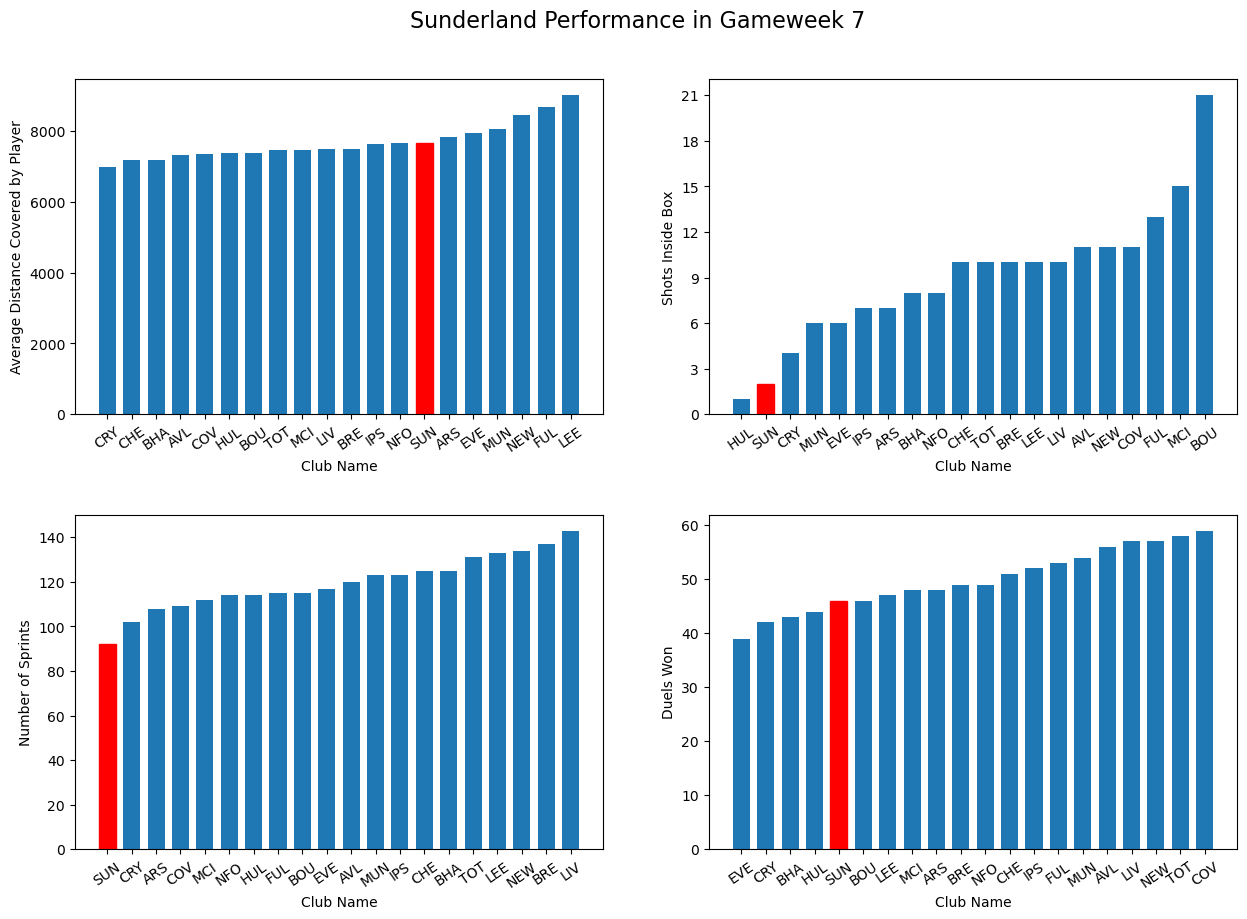

In [111]:
fig, axs = plt.subplots(2, 2, figsize=(15,10))

barlist1 = axs[0,0].bar(teams_sort_avg_distance_cov["short_name"], teams_sort_avg_distance_cov["avg_distance_cov"], width=.7)
axs[0,0].set_xlabel("Club Name")
# axs[0,0].set_title("GW7: Average Distance Covered by Player")
axs[0,0].set_ylabel("Average Distance Covered by Player")
barlist1[13].set_color('r')

barlist2 = axs[0,1].bar(teams_sort_shots_box["short_name"], teams_sort_shots_box["shots_inside_box"], width=.7)
axs[0,1].set_xlabel("Club Name")
axs[0,1].set_ylabel("Shots Inside Box")
barlist2[1].set_color('r')
axs[0,1].yaxis.set_major_locator(MaxNLocator(integer=True, min_n_ticks=1))

barlist3 = axs[1,1].bar(teams_sort_duels_won["short_name"], teams_sort_duels_won["duels_won"], width=.7)
axs[1,1].set_xlabel("Club Name")
axs[1,1].set_ylabel("Duels Won")
barlist3[4].set_color('r')

barlist4 = axs[1,0].bar(teams_sort_number_of_sprints["short_name"], teams_sort_number_of_sprints["number_of_sprints"], width=.7)
axs[1,0].set_xlabel("Club Name")
axs[1,0].set_ylabel("Number of Sprints")
barlist4[0].set_color('r')

plt.subplots_adjust(hspace=0.3)
fig.suptitle("Sunderland Performance in Gameweek 7", fontsize=16, y=0.95)
for ax in axs.flatten():
    ax.tick_params(axis='x', labelrotation=35)